In [86]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
from tqdm import tqdm

plt.rcParams['figure.figsize'] = [8.0, 8.0]
plt.rcParams['figure.dpi'] = 140



_EPS_ = 1e-6

In [96]:
#@njit
def run_abp_core(x, y, phi, dt, tau_func,
                 Pe=1, Dt=0, Dr=1, eps=100):
    '''
    Simulate an ABP with Euler-Maruyama steps of step width dt.
    The first entries of x, y, and phi form the initial condition,
    the rest of the entries get filled by this function, altering
    existing data.
    '''

    n_steps = x.shape[0]

    for i in range(0, n_steps-1):

        x_ = x[i]
        y_ = y[i]
        phi_ = phi[i]

        F = 0
        if x_ > -2**(-1/6):
            F = 24*eps*((1/(x_+_EPS_))**13 - 2*(1/(x_+_EPS_))**7)

        torque = tau_func(phi_) * F

        dx = np.cos(phi_) * Pe
        dy = np.sin(phi_) * Pe

        x[i+1] = x_ + dx * dt + np.random.normal(0, np.sqrt(2*Dt*dt)) + F * dt

        if x[i+1] > 0:
            x[i+1] = 0

        y[i+1] = y_ + dy * dt + np.random.normal(0, np.sqrt(2*Dt*dt))
        phi[i+1] = phi_ + np.random.normal(0, np.sqrt(2*Dr*dt)) - torque * dt

def plot_trajectory(x, y, phi):
    plt.figure(figsize=(8, 8))
    plt.plot(x[0], y[0], 'ro')
    plt.axvline(0, color='k', linestyle='--')
    plt.axvline(-2**(-1/6), color='g', linestyle='--')
    plt.gca().set_aspect('equal', adjustable='box')

    tangent_length = 0.5
    n_steps = x.shape[0]
    for i in range(0, n_steps, 10):
        plt.plot([x[i], x[i] + tangent_length*np.cos(phi[i])], [y[i], y[i] + tangent_length*np.sin(phi[i])], 'b', alpha=0.5, linewidth=0.8)

    plt.plot(x, y, 'r')
    plt.show()



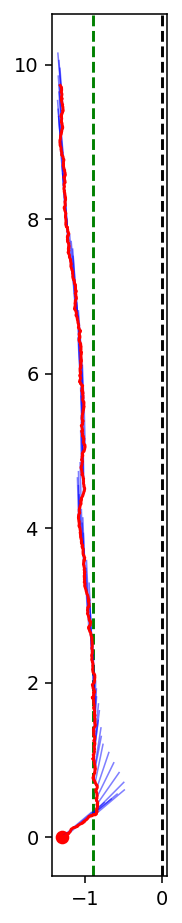

In [97]:
def generate_harmonic(k0=0, k1=0, k2=0):
    @njit
    def tau_func(phi):
        tau = k0 + k1 * np.sin(phi) + k2 * np.sin(2*phi)
        return tau
    
    @njit
    def tau_func_deriv(phi):
        tau = k1 * np.cos(phi) + 2 * k2 * np.cos(2*phi)
        return tau
    
    return tau_func, tau_func_deriv

N = 1000
x0 = -1.3
y0 = 0
phi0 = 40 * np.pi / 180
x = np.ones(N) * x0
y = np.ones(N) * y0
phi = np.ones(N) * phi0

dt = 0.01
Pe = 1
eps = 1e-2

Dt = 1e-3
Dr = 1e-4

k1_gt = 2
k2_gt = 1

tau, dtau = generate_harmonic(k0=0, k1=k1_gt, k2=k2_gt)
run_abp_core(x, y, phi, dt, tau, Pe=Pe, Dt=Dt, Dr=Dr, eps=eps)
plot_trajectory(x, y, phi)



-967.4679403022751


Text(0.5, 1.0, 'k = 1000')

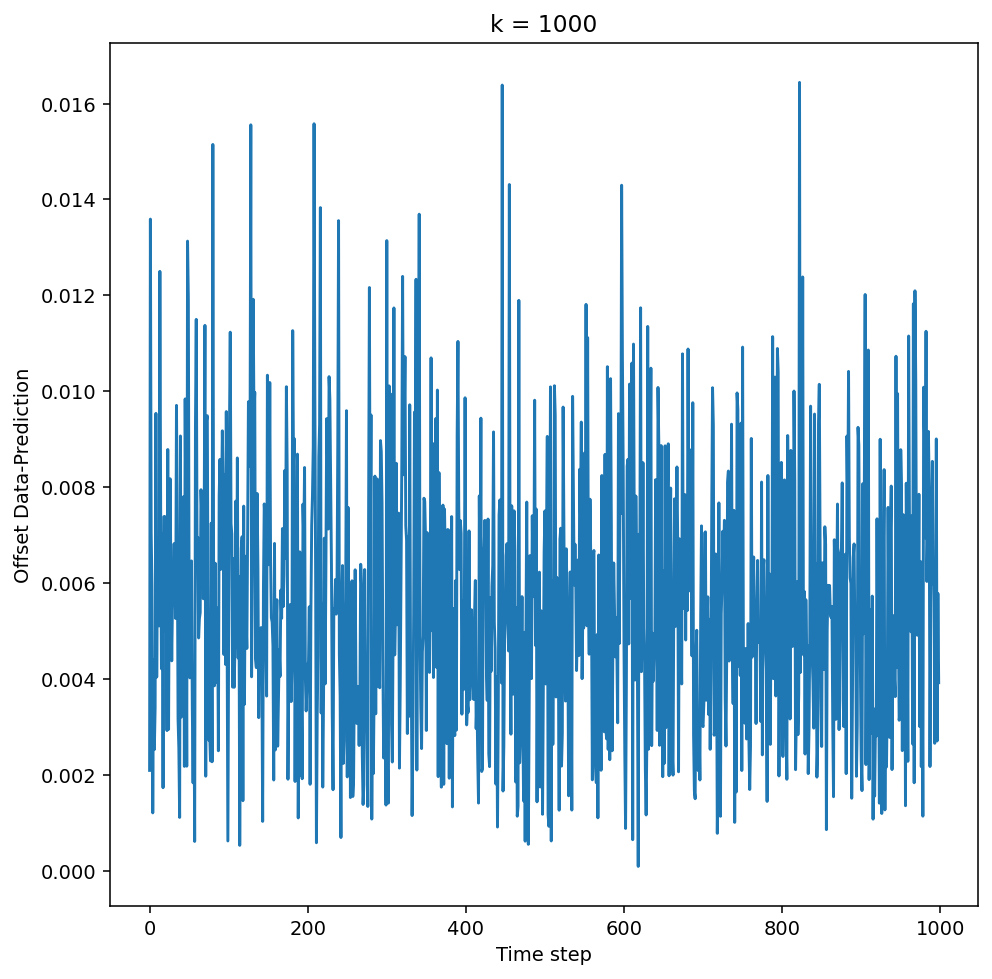

In [98]:
def calc_logl(x, y, dt, tau_func, tau_deriv_func,
            Pe=1, Dt=0, Dr=1, eps=100):
      
    logl = 0
    n_steps = x.shape[0]
    phi_posterior_mean = np.zeros(n_steps-1)
    phi_posterior_std = np.zeros(n_steps-1)
    distance_from_projection = np.zeros(n_steps-1)


    phi_mean = phi0
    phi_std = 5 * np.pi / 180

    for i in range(0, n_steps-1):

        phi_posterior_mean[i] = phi_mean
        phi_posterior_std[i] = phi_std

        F = 0.
        if x[i] > -2**(-1/6):
            F = 24*eps*((1/(x[i]+_EPS_))**13 - 2*(1/(x[i]+_EPS_))**7)

        x_projection = np.cos(phi_mean) * dt * Pe
        y_projection = np.sin(phi_mean) * dt * Pe
        projection_normalization = np.sqrt(x_projection**2 + y_projection**2)

        x_projected = x[i] + x_projection
        y_projected = y[i] + y_projection

        dx = x_projected - (x[i+1] - F * dt)
        dy = y_projected - y[i+1]

        d = np.sqrt(dx**2 + dy**2)
        distance_std = np.sqrt(np.sqrt(2 * Dt * dt)**2 + (phi_std * Pe * dt)**2)

        logl += -0.5 * (d**2) / distance_std**2

        offset = (-dy * x_projection / projection_normalization) + (dx * y_projection / projection_normalization)
        phi_offset_mean = offset / (Pe * dt)
        phi_offset_std = np.sqrt(2 * Dt * dt) / (Pe * dt)

        phi_mean = (phi_std**2 * (phi_mean + phi_offset_mean) + phi_offset_std**2 * phi_mean) / (phi_std**2 + phi_offset_std**2)
        phi_std = np.sqrt(1 / (1/phi_std**2 + 1/phi_offset_std**2) + 2 * Dr * dt)

        distance_from_projection[i] = d

        torque = tau_func(phi_mean) * F
        d_torque = tau_deriv_func(phi_mean) * F
        phi_mean += - torque * dt
        phi_std *= np.exp(-d_torque * dt)

    return dict(logl=logl,
                distance_from_projection=distance_from_projection,
                phi_posterior_mean=phi_posterior_mean,
                phi_posterior_std=phi_posterior_std)

tau, dtau = generate_harmonic(k0=0, k1=k1_gt, k2=k2_gt)
res = calc_logl(x, y, dt=dt, tau_func=tau, tau_deriv_func=dtau, Pe=Pe, Dt=Dt, Dr=Dr, eps=1e-2)
plt.plot(res['distance_from_projection'])
print(res['logl'])
plt.xlabel('Time step')
plt.ylabel('Offset Data-Prediction')
plt.title("k = 1000")

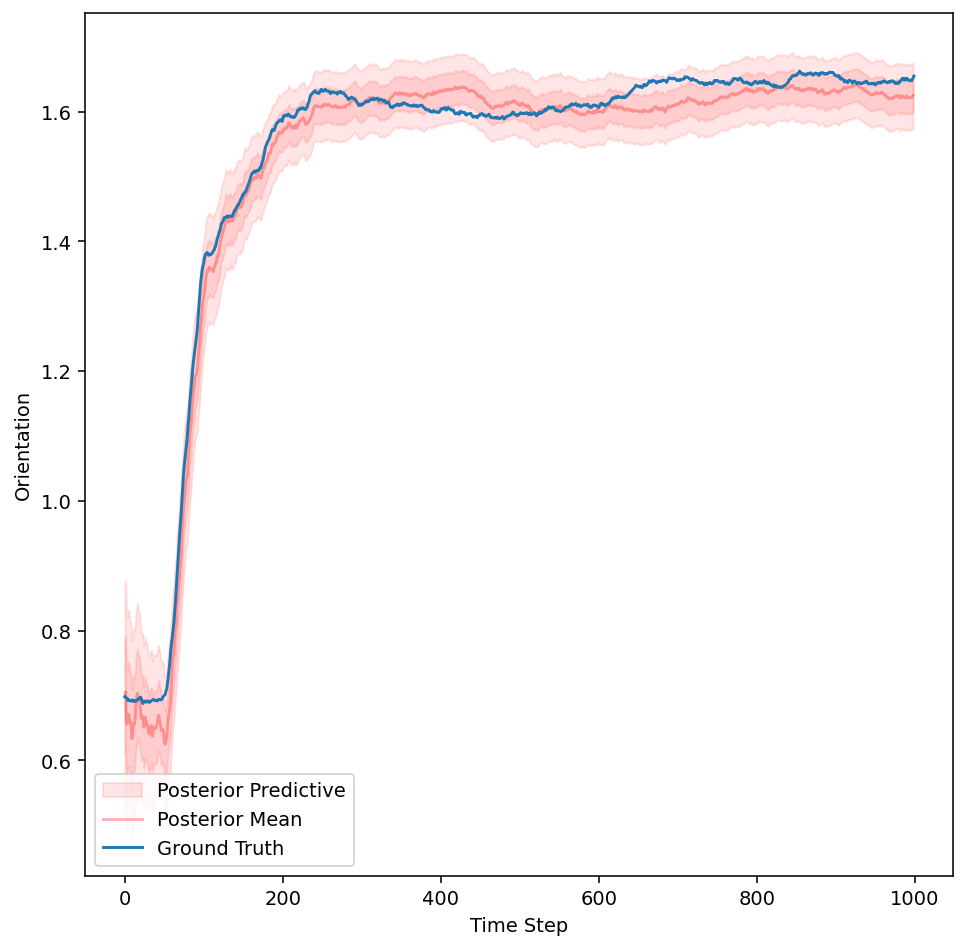

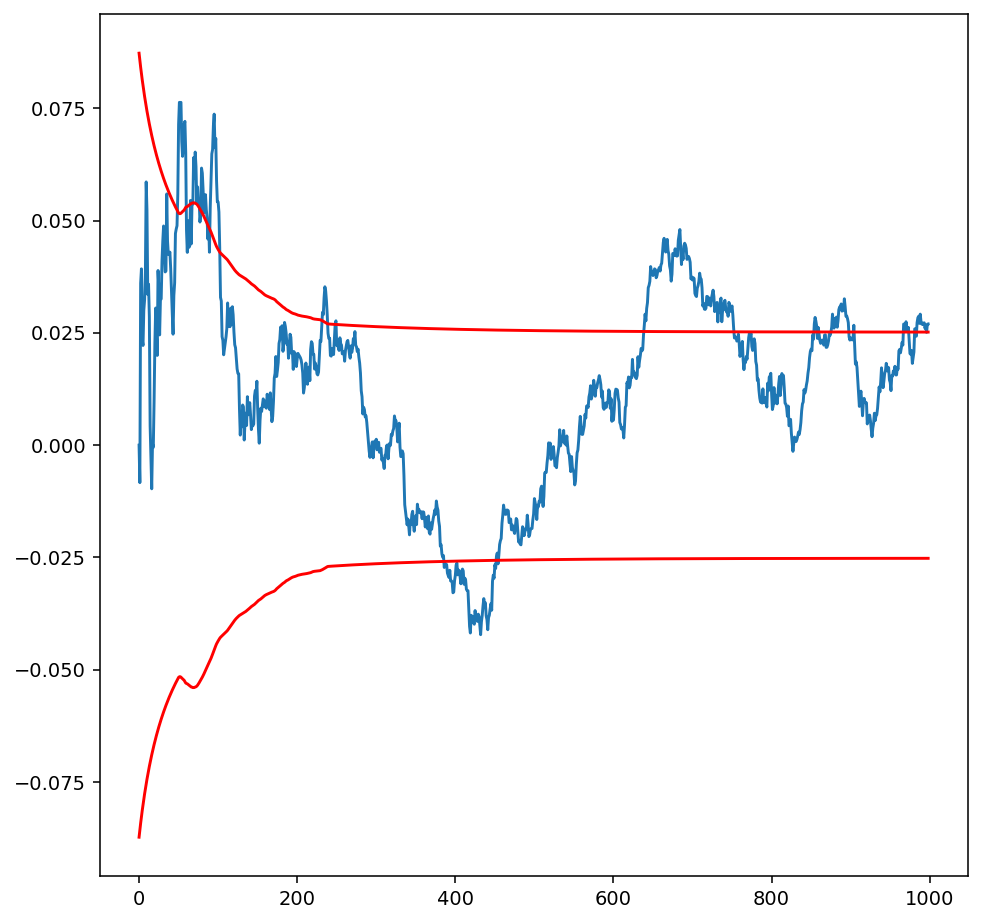

In [101]:
phi_post = res['phi_posterior_mean']
phi_post_std = res['phi_posterior_std']
plt.fill_between(range(phi_post.shape[0]), phi_post - 2*phi_post_std, phi_post + 2*phi_post_std, color='r', alpha=0.1)
plt.fill_between(range(phi_post.shape[0]), phi_post - phi_post_std, phi_post + phi_post_std, color='r', alpha=0.1, label='Posterior Predictive')
plt.plot(phi_post, 'r', label='Posterior Mean', alpha=0.3)

plt.plot(phi, label='Ground Truth')
plt.xlabel('Time Step')
plt.ylabel('Orientation')
plt.legend()

plt.show()

# plot the difference between the ground truth and the posterior mean
plt.plot(phi[:-1] - phi_post)
plt.plot(phi_post_std, color='r')
plt.plot(-phi_post_std, color='r') 



100%|██████████| 100/100 [00:04<00:00, 24.50it/s]


Text(0, 0.5, 'Poster density')

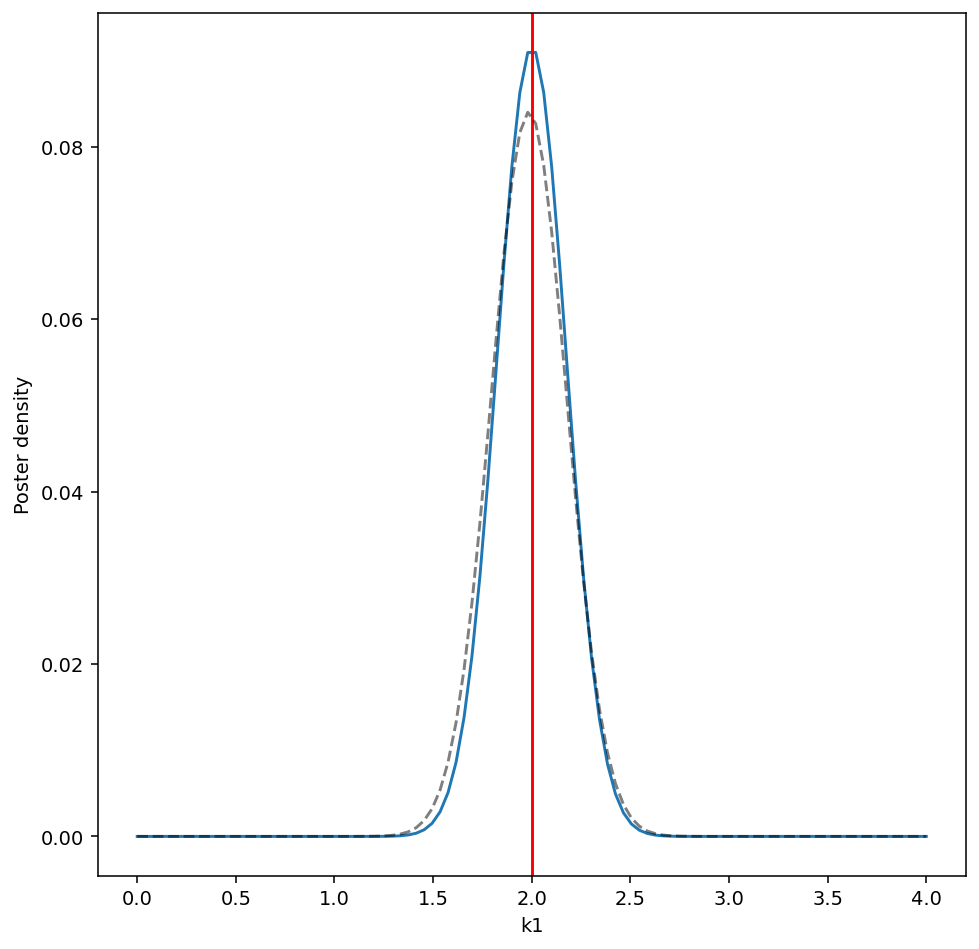

In [91]:
k1 = np.linspace(0, 2 * k1_gt, 100)
logls = []

for k1_ in tqdm(k1):
    tau, dtau = generate_harmonic(k0=0, k1=k1_, k2=k2_gt)
    res = calc_logl(x, y, dt=dt, tau_func=tau, tau_deriv_func=dtau, Pe=Pe, Dt=Dt, Dr=Dr, eps=1e-2)
    logls.append(res['logl'])

logls = np.array(logls)
logls -= np.max(logls)
p = np.exp(logls)
p /= np.sum(p)
plt.plot(k1, p)
plt.axvline(k1_gt, color='r')
plt.xlabel('k1')
plt.ylabel('Poster density')

logls = []
for k1_ in tqdm(k1):
    tau, dtau = generate_harmonic(k0=0, k1=k1_, k2=k2_gt)
    res = calc_logl(x, y, dt=dt, tau_func=tau, tau_deriv_func=lambda phi: 0, Pe=Pe, Dt=Dt, Dr=Dr, eps=1e-2)
    logls.append(res['logl'])

logls = np.array(logls)
logls -= np.max(logls)
p = np.exp(logls)
p /= np.sum(p)
plt.plot(k1, p, '--k', alpha=0.5)
plt.xlabel('k1')
plt.ylabel('Poster density')


In [92]:
resolution =  60
k2_max = 3
k1 = np.linspace(0, 2 * k1_gt, resolution)
k2 = np.linspace(0, 2 * k2_gt, resolution)
logls = []

for k1_ in tqdm(k1):
    for k2_ in k2:
        tau, dtau = generate_harmonic(k0=0, k1=k1_, k2=k2_)
        res = calc_logl(x, y, dt=dt, tau_func=tau, tau_deriv_func=dtau, Pe=Pe, Dt=Dt, Dr=Dr, eps=1e-2)
        logls.append(res['logl'])

logls = np.array(logls)
logls -= np.max(logls)
p = np.exp(logls)
p /= np.sum(p)
# reshape logls to a 2D grid
p = p.reshape((resolution, resolution)).T

  2%|▏         | 1/60 [00:06<06:02,  6.14s/it]


KeyboardInterrupt: 

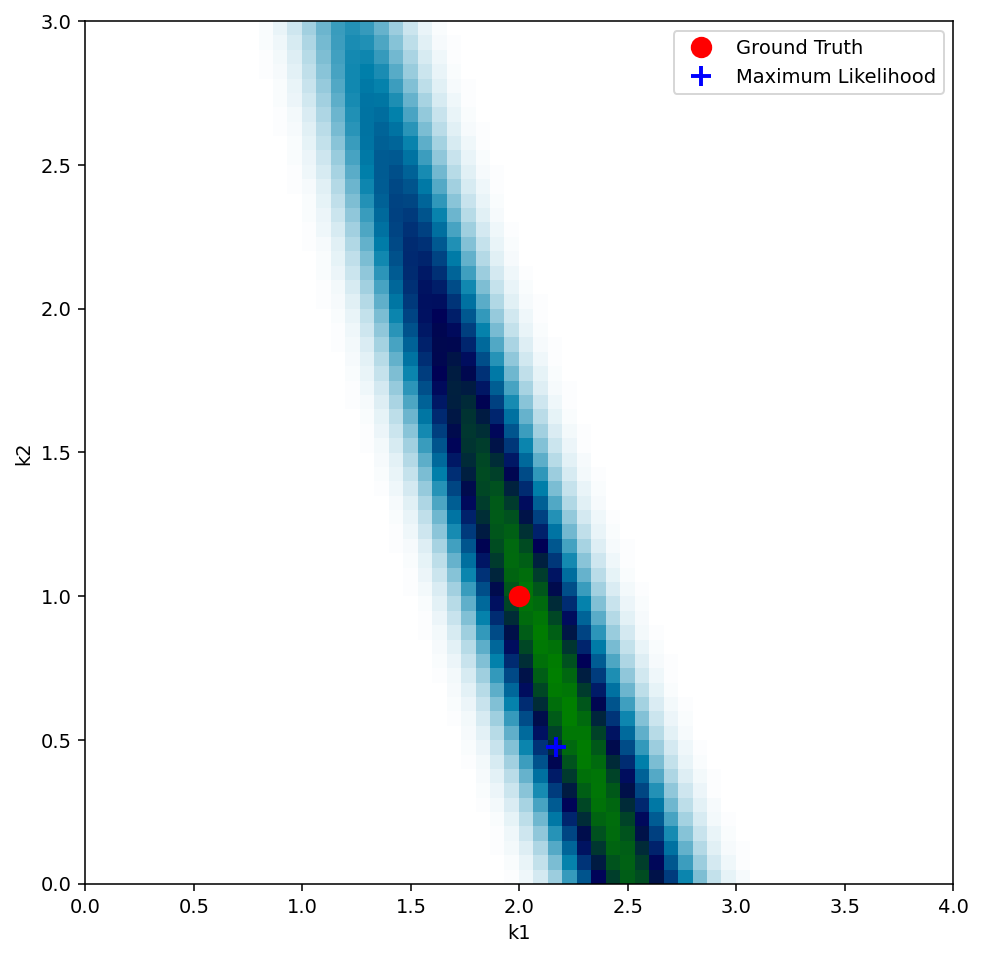

In [ ]:
plt.imshow(p, extent=(0, 2*k1_gt, 0, k2_max), origin='lower', aspect='auto', cmap='ocean_r')
plt.xlabel('k1')
plt.ylabel('k2')
plt.plot(k1_gt, k2_gt, 'ro', markersize=10, label='Ground Truth')

# draw the 2d location of the maximum of 2d array p
i, j = np.unravel_index(np.argmax(p), p.shape)
plt.plot(k1[j], k2[i], 'b+', markersize=10, markeredgewidth=2, label='Maximum Likelihood')
plt.legend()